In [21]:
import re
import string
import pandas as pd
import nltk

from pathlib import Path
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from gensim.models import Word2Vec

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [2]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LOQ\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LOQ\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LOQ\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\LOQ\AppData\Roaming\nltk_data...
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LOQ\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [3]:
file_path = Path(r"D:\ECU\NLP\nlp-task1\autonomous_vehicles.txt")

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

print("Text length:", len(text))
print(text[:1000])

Text length: 54123
A self-driving car, also known as an autonomous car, driverless car, robotic car, or robo-car, is a car that is capable of operating with reduced or no human input.[1] They are sometimes called robotaxis, though this term refers specifically to self-driving cars operated for a ridesharing company. As of 2026[update], the term "self-driving" lacks an agreed standard definition and is also subject to commercial advertising and branding considerations.

In 2020, Waymo was the first to offer rides in driverless taxis in the operational design domain (ODD) of limited geographic areas, but as of late 2025[update], no system has achieved full autonomy in all domains - sometimes referred to as "Level 5" on a scale of 0 to 5 levels of automation defined by the global standards organization SAE International, or simply "no driver" as given by the classification system proposed by Mobileye in the US.

Following a history of experimentation and development of advanced driver ass

In [4]:
print("Characters:", len(text))
print("Words:", len(text.split()))
print("Lines:", len(text.splitlines()))
print("Missing text:", len(text.strip()) == 0)

Characters: 54123
Words: 8080
Lines: 314
Missing text: False


In [5]:
text_lower = text.lower()

print(text_lower[:500])

a self-driving car, also known as an autonomous car, driverless car, robotic car, or robo-car, is a car that is capable of operating with reduced or no human input.[1] they are sometimes called robotaxis, though this term refers specifically to self-driving cars operated for a ridesharing company. as of 2026[update], the term "self-driving" lacks an agreed standard definition and is also subject to commercial advertising and branding considerations.

in 2020, waymo was the first to offer rides i


In [6]:
text_clean = re.sub(r'https?://\S+|www\.\S+', '', text_lower)
text_clean = re.sub(r'<[^>]+>', '', text_clean)

print(text_clean[:500])

a self-driving car, also known as an autonomous car, driverless car, robotic car, or robo-car, is a car that is capable of operating with reduced or no human input.[1] they are sometimes called robotaxis, though this term refers specifically to self-driving cars operated for a ridesharing company. as of 2026[update], the term "self-driving" lacks an agreed standard definition and is also subject to commercial advertising and branding considerations.

in 2020, waymo was the first to offer rides i


In [7]:
text_clean = re.sub(r'\d+', ' ', text_clean)
text_clean = text_clean.translate(
    str.maketrans('', '', string.punctuation)
)
text_clean = re.sub(r'\s+', ' ', text_clean).strip()

print(text_clean[:500])

a selfdriving car also known as an autonomous car driverless car robotic car or robocar is a car that is capable of operating with reduced or no human input they are sometimes called robotaxis though this term refers specifically to selfdriving cars operated for a ridesharing company as of update the term selfdriving lacks an agreed standard definition and is also subject to commercial advertising and branding considerations in waymo was the first to offer rides in driverless taxis in the operat


In [8]:
tokens = word_tokenize(text_clean)

print("Number of tokens:", len(tokens))
print(tokens[:50])

Number of tokens: 7809
['a', 'selfdriving', 'car', 'also', 'known', 'as', 'an', 'autonomous', 'car', 'driverless', 'car', 'robotic', 'car', 'or', 'robocar', 'is', 'a', 'car', 'that', 'is', 'capable', 'of', 'operating', 'with', 'reduced', 'or', 'no', 'human', 'input', 'they', 'are', 'sometimes', 'called', 'robotaxis', 'though', 'this', 'term', 'refers', 'specifically', 'to', 'selfdriving', 'cars', 'operated', 'for', 'a', 'ridesharing', 'company', 'as', 'of', 'update']


In [9]:
stop_words = set(stopwords.words('english'))

tokens_no_stopwords = [
    word for word in tokens
    if word not in stop_words
]

print("Tokens before:", len(tokens))
print("Tokens after:", len(tokens_no_stopwords))
print(tokens_no_stopwords[:50])

Tokens before: 7809
Tokens after: 4895
['selfdriving', 'car', 'also', 'known', 'autonomous', 'car', 'driverless', 'car', 'robotic', 'car', 'robocar', 'car', 'capable', 'operating', 'reduced', 'human', 'input', 'sometimes', 'called', 'robotaxis', 'though', 'term', 'refers', 'specifically', 'selfdriving', 'cars', 'operated', 'ridesharing', 'company', 'update', 'term', 'selfdriving', 'lacks', 'agreed', 'standard', 'definition', 'also', 'subject', 'commercial', 'advertising', 'branding', 'considerations', 'waymo', 'first', 'offer', 'rides', 'driverless', 'taxis', 'operational', 'design']


In [10]:
lemmatizer = WordNetLemmatizer()

lemmatized_tokens = [
    lemmatizer.lemmatize(word)
    for word in tokens_no_stopwords
]

print(lemmatized_tokens[:50])

['selfdriving', 'car', 'also', 'known', 'autonomous', 'car', 'driverless', 'car', 'robotic', 'car', 'robocar', 'car', 'capable', 'operating', 'reduced', 'human', 'input', 'sometimes', 'called', 'robotaxis', 'though', 'term', 'refers', 'specifically', 'selfdriving', 'car', 'operated', 'ridesharing', 'company', 'update', 'term', 'selfdriving', 'lack', 'agreed', 'standard', 'definition', 'also', 'subject', 'commercial', 'advertising', 'branding', 'consideration', 'waymo', 'first', 'offer', 'ride', 'driverless', 'taxi', 'operational', 'design']


In [11]:
prepared_text = " ".join(lemmatized_tokens)

print(prepared_text[:1000])
print("\nFinal word count:", len(lemmatized_tokens))

selfdriving car also known autonomous car driverless car robotic car robocar car capable operating reduced human input sometimes called robotaxis though term refers specifically selfdriving car operated ridesharing company update term selfdriving lack agreed standard definition also subject commercial advertising branding consideration waymo first offer ride driverless taxi operational design domain odd limited geographic area late update system achieved full autonomy domain sometimes referred level scale level automation defined global standard organization sae international simply driver given classification system proposed mobileye u following history experimentation development advanced driver assistance system ada world war ii two main technology primarily used lidar light detection ranging visual sensor camera capture image video like human eye combined system global positioning system gps neural network artificial intelligence established ada engineering deliver level driving au

In [12]:
tokens = re.findall(r"\b[a-zA-Z]+\b", prepared_text.lower())

print(tokens[:20])

['selfdriving', 'car', 'also', 'known', 'autonomous', 'car', 'driverless', 'car', 'robotic', 'car', 'robocar', 'car', 'capable', 'operating', 'reduced', 'human', 'input', 'sometimes', 'called', 'robotaxis']


In [13]:
from collections import Counter

unigrams = Counter(tokens)

bigrams = Counter(
    zip(tokens, tokens[1:])
)

trigrams = Counter(
    zip(tokens, tokens[1:], tokens[2:])
)

print("Top 10 Unigrams:")
print(unigrams.most_common(10))

print("\nTop 10 Bigrams:")
print(bigrams.most_common(10))

print("\nTop 10 Trigrams:")
print(trigrams.most_common(10))

Top 10 Unigrams:
[('vehicle', 116), ('car', 96), ('system', 81), ('level', 74), ('driver', 74), ('driving', 57), ('autonomous', 43), ('selfdriving', 37), ('automated', 37), ('road', 36)]

Top 10 Bigrams:
[(('selfdriving', 'car'), 20), (('autonomous', 'vehicle'), 18), (('automated', 'vehicle'), 10), (('human', 'driver'), 9), (('automated', 'driving'), 8), (('driving', 'system'), 8), (('autonomous', 'car'), 6), (('driverless', 'car'), 6), (('level', 'capability'), 6), (('driver', 'assistance'), 5)]

Top 10 Trigrams:
[(('automated', 'driving', 'system'), 5), (('operational', 'design', 'domain'), 4), (('design', 'domain', 'odd'), 4), (('advanced', 'driver', 'assistance'), 4), (('driver', 'assistance', 'system'), 3), (('would', 'feel', 'safe'), 3), (('full', 'selfdriving', 'fsd'), 3), (('driving', 'system', 'ad'), 3), (('km', 'per', 'mile'), 3), (('also', 'known', 'autonomous'), 2)]


In [38]:
sentences = [
    re.findall(r"\b[a-zA-Z]+\b", sentence.lower())
    for sentence in re.split(r"[.!?\n]+", prepared_text)
]

sentences = [s for s in sentences if s]

model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=3,
    min_count=2,
    sg=1,
    seed=42
)

print("Vocabulary size:", len(model.wv))

Vocabulary size: 739


In [39]:
# Word embedding for "cat"
print(model.wv["vehicle"])

[ 3.27135026e-02  2.98715406e-03 -6.44279498e-05  2.05928367e-02
 -2.16361471e-02  3.71872708e-02  3.52709070e-02  5.59038706e-02
 -3.50527242e-02 -8.45957175e-03 -1.00522839e-01  3.76710705e-02
 -6.33763336e-03  8.19893181e-02 -2.53742859e-02 -7.12686777e-02
  4.82517593e-02 -1.28666580e-01 -4.50436249e-02 -5.24208695e-03
 -9.15151183e-03  1.55590195e-02  1.79155674e-02  9.09809917e-02
  5.65931946e-02  4.97822417e-03 -6.11961670e-02  5.83658330e-02
 -4.12872024e-02 -7.93780833e-02 -1.32836457e-02 -3.38091813e-02
  3.19014100e-04 -1.76992696e-02  1.25287604e-02 -4.38602827e-02
  5.19968309e-02 -1.02512680e-01 -6.86777476e-03  4.52211872e-02
  2.22155787e-02  7.22947298e-03  9.03480425e-02 -1.52200321e-02
  2.64998265e-02  1.92258600e-02  3.99704985e-02  6.17206767e-02
  9.61677656e-02 -6.75037652e-02 -1.88388322e-02 -1.31919071e-01
  6.25701970e-04 -4.52213734e-03  5.46997376e-02 -2.51920596e-02
 -6.95184022e-02  9.80027486e-03 -7.19074672e-03  6.30418882e-02
  2.33395845e-02 -2.53385

In [40]:
# Similarity between two words
print(model.wv.similarity("vehicle", "car"))

0.9870876


In [41]:
# Most similar words
print(model.wv.most_similar("vehicle"))

[('car', 0.9870877265930176), ('system', 0.9845817685127258), ('level', 0.984208345413208), ('driver', 0.9807231426239014), ('autonomous', 0.977087676525116), ('safety', 0.9763566851615906), ('tesla', 0.9745696783065796), ('use', 0.9723708033561707), ('selfdriving', 0.9723358154296875), ('human', 0.9714955687522888)]


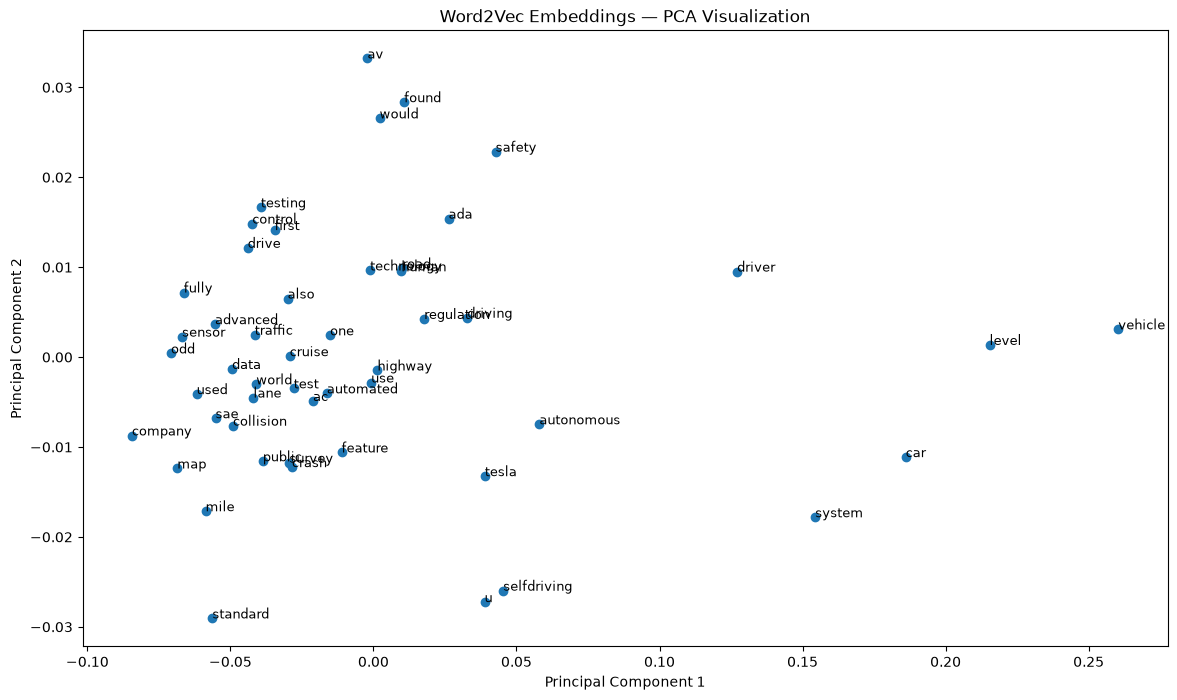

In [42]:
words = list(model.wv.index_to_key)[:50]
vectors = model.wv[words]

pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(vectors)

plt.figure(figsize=(14, 8))

plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1])

for i, word in enumerate(words):
    plt.annotate(
        word,
        (reduced_vectors[i, 0], reduced_vectors[i, 1]),
        fontsize=9
    )

plt.title("Word2Vec Embeddings — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()